# House prices

`archive/Housing.csv` has 545 houses. Each row is one house. `price` is the sale price. The other columns are the lot area, bedrooms, bathrooms, stories, parking spaces, and six yes/no facts: main road, guest room, basement, hot water heating, air conditioning, and a preferred area. `furnishingstatus` is furnished, semi-furnished, or unfurnished.

Three linear regressions are kept. One predicts the price. One predicts the log of price, and the predictions are converted back with `exp`. One does that and replaces area with the log of area.

Five folds of the training houses compare them. The 109 held-out houses are scored after that.


## Load the dataset


In [1]:
import pandas as pd

df = pd.read_csv("archive/Housing.csv")
print(df.shape)
print(df.columns.tolist())


(545, 13)
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']


## Inspect the data

`df` is `archive/Housing.csv`. There are 545 rows, 13 columns, and no missing values. `price`, `area`, `bedrooms`, `bathrooms`, `stories`, and `parking` are numbers. The six yes/no columns and `furnishingstatus` are text.

The model keeps every column except `price`, which is the target.


In [2]:
print(df.head())
print(df.shape)
df.info()
print(df.describe())
print(df.isnull().sum())


      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  
(545, 13)
<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 colum

## Investigate the target

Prices run from 1,750,000 to 13,300,000. The mean is 4,766,729 and the median is 4,340,000, so the expensive houses pull the mean above the middle.

Area and bathrooms move with price. Their correlations are 0.536 and 0.518. Stories, parking, and bedrooms follow at 0.421, 0.384, and 0.366.

Air conditioning splits the prices: 6,013,221 with it, across 172 houses, and 4,191,940 without it, across 373. A preferred area averages 5,879,046 against 4,425,299. Furnished houses average 5,495,696, semi-furnished 4,907,524, and unfurnished 4,013,831.

Hot water heating is rare. Twenty-five houses have it, at a mean of 5,559,960, against 4,728,593 without it.

Bedrooms rise from two to four, and the ends are thin. Two bedrooms average 3,632,022 across 136 houses, three average 4,954,598 across 300, and four average 5,729,758 across 95. One bedroom and six bedrooms are two houses each.


In [3]:
print(df["price"].agg(["min", "median", "mean", "max"]).round(0))
print()
print(df[["area", "bedrooms", "bathrooms", "stories", "parking", "price"]].corr()["price"].round(3))
print()
for column in [
    "mainroad",
    "guestroom",
    "basement",
    "hotwaterheating",
    "airconditioning",
    "prefarea",
    "furnishingstatus",
    "bedrooms",
    "bathrooms",
    "stories",
    "parking",
]:
    print(column)
    print(df.groupby(column)["price"].agg(["count", "mean"]).round(0))
    print()


min        1750000.0
median     4340000.0
mean       4766729.0
max       13300000.0
Name: price, dtype: float64

area         0.536
bedrooms     0.366
bathrooms    0.518
stories      0.421
parking      0.384
price        1.000
Name: price, dtype: float64

mainroad
          count       mean
mainroad                  
no           77  3398905.0
yes         468  4991777.0

guestroom
           count       mean
guestroom                  
no           448  4544546.0
yes           97  5792897.0

basement
          count       mean
basement                  
no          354  4509966.0
yes         191  5242615.0

hotwaterheating
                 count       mean
hotwaterheating                  
no                 520  4728593.0
yes                 25  5559960.0

airconditioning
                 count       mean
airconditioning                  
no                 373  4191940.0
yes                172  6013221.0

prefarea
          count       mean
prefarea                  
no          417 

## Visualise relationships

The pairplot crosses price with area, bedrooms, bathrooms, stories, and parking. Area and bathrooms rise with price. Bedrooms, stories, and parking rise more loosely, and the highest prices sit on the larger lots.


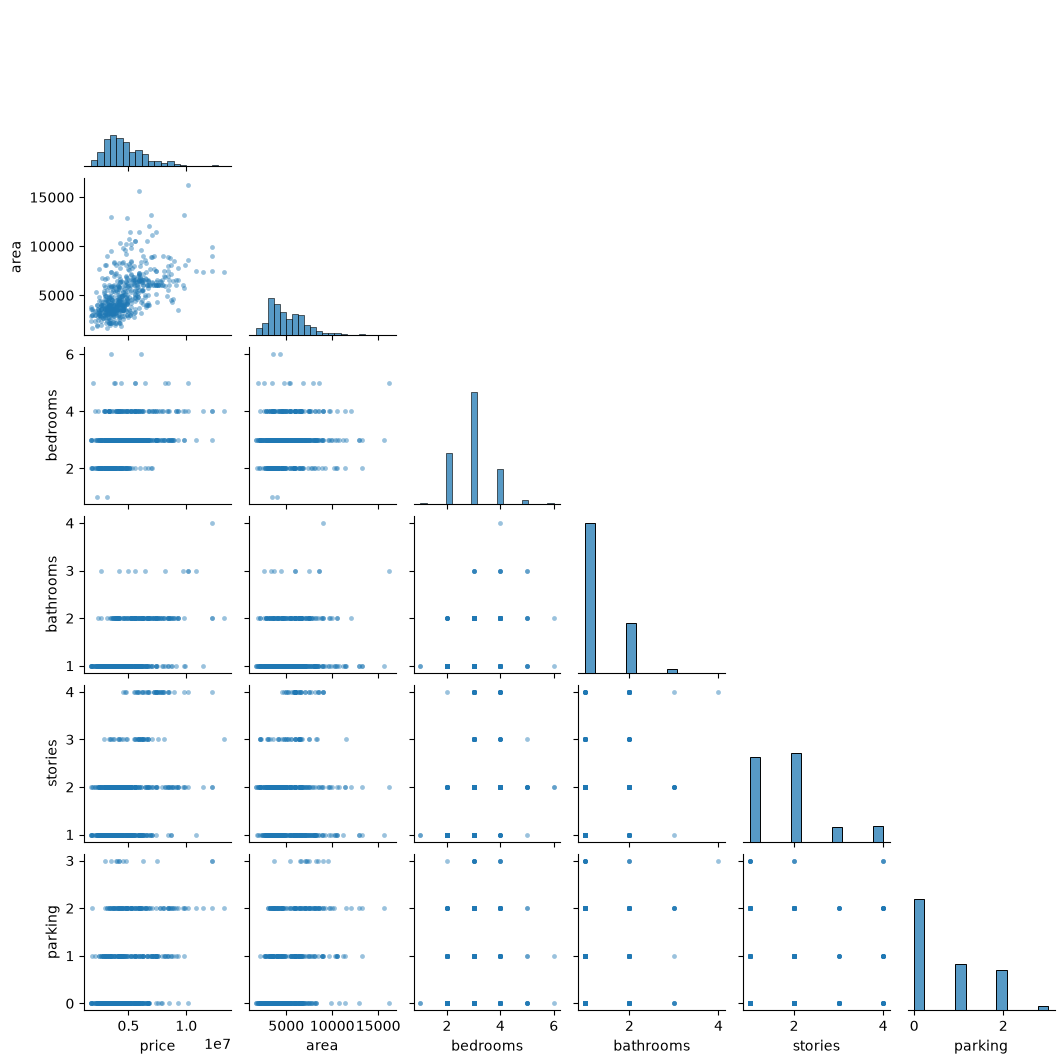

In [4]:
%matplotlib inline

import matplotlib.pyplot as plt
import seaborn as sns

sns.pairplot(
    df[["price", "area", "bedrooms", "bathrooms", "stories", "parking"]],
    corner=True,
    diag_kind="hist",
    height=1.8,
    plot_kws={"s": 12, "alpha": 0.45, "linewidth": 0, "color": "#1F78B4"},
    diag_kws={"color": "#1F78B4"},
)
plt.show()


## Train and test split

Hold out 20% of the houses. `price` is a continuous amount, so the split is not stratified. Both sets keep the same columns.


In [5]:
from sklearn.model_selection import train_test_split

model_columns = [
    "area",
    "bedrooms",
    "bathrooms",
    "stories",
    "parking",
    "mainroad",
    "guestroom",
    "basement",
    "hotwaterheating",
    "airconditioning",
    "prefarea",
    "furnishingstatus",
]
features = df[model_columns]
labels = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.2, random_state=42
)
print("Train:", X_train.shape[0], "Test:", X_test.shape[0])
print(y_train.agg(["min", "median", "mean", "max"]).round(0))
print(y_test.agg(["min", "median", "mean", "max"]).round(0))


Train: 436 Test: 109
min        1750000.0
median     4291000.0
mean       4706527.0
max       12250000.0
Name: price, dtype: float64
min        1750000.0
median     4550000.0
mean       5007537.0
max       13300000.0
Name: price, dtype: float64


## The three lines

Each yes/no fact becomes a single yes column. No is the reference. `furnishingstatus` keeps semi-furnished and unfurnished, both compared with furnished.

Area, bedrooms, bathrooms, stories, and parking are scaled on the training houses inside each fold. The log-price lines are scored after `exp`, in the original prices.


In [6]:
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
categorical_features = [
    'mainroad',
    'guestroom',
    'basement',
    'hotwaterheating',
    'airconditioning',
    'prefarea',
    'furnishingstatus',
]


def prepared(frame, log_area):
    out = frame.copy()
    if log_area:
        out['area'] = np.log(out['area'])
    return out


def price_pipeline():
    return Pipeline(
        [
            (
                'preprocess',
                ColumnTransformer(
                    [
                        ('numeric', StandardScaler(), numeric_features),
                        (
                            'categorical',
                            OneHotEncoder(drop='first', sparse_output=False),
                            categorical_features,
                        ),
                    ]
                ),
            ),
            ('regressor', LinearRegression()),
        ]
    )


def predict_prices(model, features, log_price):
    predicted = model.predict(features)
    if log_price:
        predicted = np.exp(predicted)
    return predicted


models = [
    ('Price', False, False),
    ('Log price', True, False),
    ('Log price and log area', True, True),
]


## Cross-validation

Five folds of the 436 training houses score each line. The folds are shuffled with `random_state=42`. A fold's mean absolute error and R² use the original prices. The 109 held-out houses stay out of these folds.


In [7]:
folds = KFold(n_splits=5, shuffle=True, random_state=42)

for name, log_price, log_area in models:
    features = prepared(X_train, log_area)
    fold_errors = []
    fold_r2 = []
    for train_index, valid_index in folds.split(features):
        fold_model = price_pipeline()
        y_fold = y_train.iloc[train_index]
        if log_price:
            y_fold = np.log(y_fold)
        fold_model.fit(features.iloc[train_index], y_fold)
        predicted = predict_prices(fold_model, features.iloc[valid_index], log_price)
        truth = y_train.iloc[valid_index]
        fold_errors.append(mean_absolute_error(truth, predicted))
        fold_r2.append(r2_score(truth, predicted))
    print(name)
    print(f'Mean absolute error: {np.mean(fold_errors):,.0f}')
    print('Folds:', ', '.join(f'{error:,.0f}' for error in fold_errors))
    print(f'R2: {np.mean(fold_r2):.3f}')
    print('Folds:', ', '.join(f'{score:.3f}' for score in fold_r2))
    print()


Price
Mean absolute error: 747,209
Folds: 795,581, 704,819, 752,003, 756,147, 727,495
R2: 0.649
Folds: 0.634, 0.596, 0.730, 0.658, 0.628



Log price
Mean absolute error: 723,005
Folds: 768,790, 707,659, 682,239, 722,050, 734,287
R2: 0.658
Folds: 0.646, 0.575, 0.779, 0.657, 0.631

Log price and log area
Mean absolute error: 703,761
Folds: 756,700, 660,056, 698,092, 673,843, 730,114
R2: 0.671
Folds: 0.657, 0.609, 0.770, 0.681, 0.638



## What the folds say

Log price and log area has the lowest fold error, 703,761, and the highest R², 0.671. Log price is next, at 723,005 and 0.658. Price left as it is is 747,209 and 0.649.

The five fold errors for log area run from 660,056 to 756,700. For log price they run from 682,239 to 768,790. The gap between those two lines is smaller than the spread inside either one.


## The held-out houses

Each line is fit on all 436 training houses and scored on the 109 held-out houses. Predictions from the log lines are converted back with `exp`.


In [8]:
held_out = y_test.to_numpy()
for name, log_price, log_area in models:
    model = price_pipeline()
    y_fit = np.log(y_train) if log_price else y_train
    train_features = prepared(X_train, log_area)
    test_features = prepared(X_test, log_area)
    model.fit(train_features, y_fit)
    predicted = predict_prices(model, test_features, log_price)
    train_predicted = predict_prices(model, train_features, log_price)
    print(name)
    print(f'Train R2: {r2_score(y_train, train_predicted):.3f}')
    print(f'R2: {r2_score(held_out, predicted):.3f}')
    print(f'Mean absolute error: {mean_absolute_error(held_out, predicted):,.0f}')
    print()


Price
Train R2: 0.686
R2: 0.653
Mean absolute error: 970,043

Log price
Train R2: 0.694
R2: 0.658
Mean absolute error: 960,123

Log price and log area
Train R2: 0.704
R2: 0.659
Mean absolute error: 969,728



## What the held-out houses say

Log price has the smallest miss, 960,123, and R² 0.658. Log price and log area has R² 0.659 and mean absolute error 969,728. Price left as it is has R² 0.653 and mean absolute error 970,043.

The folds and the held-out houses pick different winners, and the two log lines stay within about 10,000 of each other on the 109 houses.


## Conclusion

`archive/Housing.csv` has 545 houses. `price` is the sale price. 436 houses train the models and 109 are held out.

The three kept lines share one encoding. Yes/no columns keep the yes side. Furnished is the reference for furnishing. Numeric columns are scaled inside each fit.

Five folds of the training houses rank log price and log area first, mean absolute error 703,761 and R² 0.671. Log price is 723,005 and 0.658. The raw price is 747,209 and 0.649.

On the 109 held-out houses, log price misses by 960,123 with R² 0.658. Log price and log area misses by 969,728 with R² 0.659. The raw price misses by 970,043 with R² 0.653.

More houses are necessary to get a better result. These 545 rows already put the three lines within about 10,000 of each other, so the remaining miss will not fall much on this file alone.
